# Assignment 1: EDA and Baseline
GROUP50_CENG313, LLM Classification Finetuning

**Contents:** 1. Problem definition · 2. Data overview · 3. Exploratory data analysis · 4. Preprocessing · 5. Baseline models · 6. Kaggle submission · 7. Conclusions

In [1]:
# Colab: clone the repo so src/ can be imported, then download the data into data/ (not committed)
# !git clone https://github.com/ceng313-2026/GROUP50_CENG313.git
# %cd GROUP50_CENG313
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss

from src.data import TARGET_COLS, load_train, load_test, length_features, encode_target, stratified_split
from src.models import class_prior_probs, build_length_model
from src.utils import set_seed, save_submission

set_seed(42)

## 1. Problem definition

**Task.** Every row of the data is one conversation in which a user sent a prompt to two different large language models (model A and model B). A human then chose the response they preferred, or declared a tie. Given the prompt and the two responses, we must predict **how likely each of the three outcomes is**. This is a three-class classification problem with probabilistic output.

**Target variable.** `winner_model_a`, `winner_model_b` and `winner_tie` are three one-hot columns: exactly one of them is 1 in every training row. In the notebook we merge them into one label: 0 = A wins, 1 = B wins, 2 = tie.

**Evaluation metric.** Multi-class **log loss** between the predicted probabilities and the true outcome (lower is better); this is stated on the competition's Evaluation page. The submission file has one probability per class. A model that ignores the input and predicts equal probabilities for all three classes scores ln 3 ≈ 1.0986, so any useful model has to beat that value.

**What the test data contains.** `test.csv` has only `id`, `prompt`, `response_a` and `response_b`. The model names (`model_a`, `model_b`) exist in the training data but **not** in the test data, so they cannot be used as features. The downloaded `test.csv` has just 3 example rows. This is a *Code Competition*: the real test set is only available inside Kaggle notebooks and its labels are hidden, so we also evaluate on a held-out split of `train.csv`.

**Our approach in this assignment.** Explore and clean-check the training data, find a simple signal (response length), and build two baselines that later models must beat: the class proportions and a logistic regression on response length.

## 2. Data overview

### 2.1 Structure, column types and class distribution

Each row compares two model conversations for the same prompts. A conversation may contain one or more turns.

id is the comparison ID.

model_a and model_b are the model names.

prompt contains user messages stored as a JSON list.

response_a and response_b contain each model's replies as JSON lists.

winner_model_a, winner_model_b and winner_tie are the outcome labels (0 or 1).

In [2]:
df = load_train()
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Each target column is 1 when that outcome was selected.
class_counts = df[TARGET_COLS].sum()
class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": (class_counts / len(df) * 100).round(2)
})
print("\nClass distribution:")
print(class_distribution.to_string())

Rows: 57477
Columns: 9

Class distribution:
                Count  Percentage
winner_model_a  20064       34.91
winner_model_b  19652       34.19
winner_tie      17761       30.90


In [3]:
# Column types and summary statistics of the numeric columns.
display(df.dtypes.rename("dtype").to_frame())
display(df[["id"] + TARGET_COLS].describe().round(3))

,dtype
id,int64
model_a,str
model_b,str
prompt,str
response_a,str
response_b,str
winner_model_a,int64
winner_model_b,int64
winner_tie,int64


,id,winner_model_a,winner_model_b,winner_tie
count,5.747700e+04,57477.000,57477.000,57477.000
mean,2.142564e+09,0.349,0.342,0.309
std,1.238327e+09,0.477,0.474,0.462
min,3.019200e+04,0.000,0.000,0.000
25%,1.071821e+09,0.000,0.000,0.000
50%,2.133658e+09,0.000,0.000,0.000
75%,3.211645e+09,1.000,1.000,1.000
max,4.294947e+09,1.000,1.000,1.000


`id` and the three winner columns are integers. `model_a`, `model_b`, `prompt`, `response_a` and `response_b` are text (pandas shows them as `object` or `str`, depending on the version). `prompt`, `response_a` and `response_b` hold **JSON-encoded lists**, one entry per conversation turn, so they must be parsed before any text analysis.

`describe()` on the three winner columns repeats the class balance: their means (0.349, 0.342, 0.309) are exactly the class proportions printed above, and they add up to 1 because the columns are one-hot. `id` is a random identifier and carries no information about the outcome.

### 2.2 Data quality (missing values, duplicates, inconsistencies)

In [4]:
# We are checking if there are any missing values in the dataset.
df.isna().sum()

id                0
model_a           0
model_b           0
prompt            0
response_a        0
response_b        0
winner_model_a    0
winner_model_b    0
winner_tie        0
dtype: int64

No column level missing values were found.

In [5]:
# Now we are checking if there is null values in the dataset.
import json

for col in ["prompt", "response_a", "response_b"]:
    affected_rows = sum([1 for i in df[col] if None in json.loads(i) or "" in json.loads(i) or " " in json.loads(i)])
    print(col, affected_rows)

prompt 5


response_a 133


response_b 143


At least one empty entry was found in 5 rows of prompt, 133 rows of response_a, and 143 rows of response_b.

In [6]:
# Check for duplicate records at three levels.
print("Fully duplicated rows:", df.duplicated().sum())

print(
    "Repeated prompt-response combinations:",
    df.duplicated(subset=["prompt", "response_a", "response_b"]).sum()
)

print(
    "Repeated prompt-response combinations with the same models:",
    df.duplicated(subset=["prompt", "model_a", "model_b", "response_a", "response_b"]).sum()
)


Fully duplicated rows: 0


Repeated prompt-response combinations: 71


Repeated prompt-response combinations with the same models: 8


No fully duplicated rows were found. However, 71 additional rows contain identical prompt-response combinations. When model names are also included in the comparison, 8 additional rows are duplicated on these selected columns. It means these 8 rows differ in IDs or winner labels.

In [7]:
# Check JSON list structure, turn types, and matching conversation lengths.
import json

invalid_structure = 0
invalid_turn_type = 0
turn_mismatch = 0

for _, row in df.iterrows():
    conversation = []

    for col in ["prompt", "response_a", "response_b"]:
        try:
            turns = json.loads(row[col])
        except (json.JSONDecodeError, TypeError):
            turns = None
        conversation.append(turns)

    if not all(isinstance(turns, list) and len(turns) > 0 for turns in conversation):
        invalid_structure += 1
        continue

    if any(turn is not None and not isinstance(turn, str)
           for turns in conversation for turn in turns):
        invalid_turn_type += 1

    prompt_turns, a_turns, b_turns = conversation
    if not (len(prompt_turns) == len(a_turns) == len(b_turns)):
        turn_mismatch += 1

print("Rows with invalid JSON, non-list values, or empty lists:", invalid_structure)
print("Rows with unexpected turn types:", invalid_turn_type)
print("Rows with mismatched conversation lengths:", turn_mismatch)


Rows with invalid JSON, non-list values, or empty lists: 0
Rows with unexpected turn types: 0
Rows with mismatched conversation lengths: 0


All conversation lists are valid, and prompt and response turn counts match in every row.

In [8]:
# Each row must have exactly one winning class marked as 1.
target_cols = ["winner_model_a", "winner_model_b", "winner_tie"]
labels = df[target_cols]

binary_values = labels.isin([0, 1]).all(axis=1)
single_winner = labels.sum(axis=1) == 1
valid_labels = binary_values & single_winner

print("Rows with values other than 0 or 1:", (~binary_values).sum())
print("Rows whose winner labels do not sum to 1:", (~single_winner).sum())
print("Rows with invalid winner labels:", (~valid_labels).sum())


Rows with values other than 0 or 1: 0
Rows whose winner labels do not sum to 1: 0
Rows with invalid winner labels: 0


All winner labels are 0 or 1, with exactly one winning class per row.

In [9]:
# Count rows with at least one null or whitespace-only turn.
for col in ["prompt", "response_a", "response_b"]:
    affected_rows = 0
    for text in df[col]:
        for turn in json.loads(text):
            if turn is None or (isinstance(turn, str) and turn.strip() == ""):
                affected_rows += 1
                break
    print(col, affected_rows)


prompt 5


response_a 133


response_b 143


The full whitespace check found 5 affected prompt rows, 133 response_a rows, and 143 response_b rows.

## 3. Exploratory data analysis

We look at four things: the balance of the target, the distribution of response lengths (including outliers), and how response length relates to the outcome.

In [10]:
# Word counts of every response (the same function is used for the model features in Section 4).
features = length_features(df)
a_words, b_words = features["a_words"], features["b_words"]

length_group = np.select(
    [a_words > b_words, b_words > a_words],
    ["A longer", "B longer"],
    default="Same length",
)

outcome = df[TARGET_COLS].idxmax(axis=1).map({
    "winner_model_a": "A wins",
    "winner_model_b": "B wins",
    "winner_tie": "Tie",
})

outcome_rates = pd.crosstab(length_group, outcome, normalize="index") * 100
display(outcome_rates.round(1))

# Pairs where both responses are exactly the same text.
identical = df["response_a"] == df["response_b"]
print(f"Rows with identical responses: {identical.sum()}; they end in a tie in {df.loc[identical, 'winner_tie'].mean() * 100:.1f}% of the cases")

col_0,A wins,B wins,Tie
row_0,,,
A longer,43.1,26.6,30.4
B longer,27.2,42.4,30.4
Same length,21.2,21.0,57.8


Rows with identical responses: 275; they end in a tie in 90.2% of the cases


This table is the numeric version of the third plot below. When response A is longer, A wins in 43.1% of the comparisons and B in 26.6%. When B is longer, B wins in 42.4% and A in 27.2%. Equal length gives a tie in 57.8% of the cases.

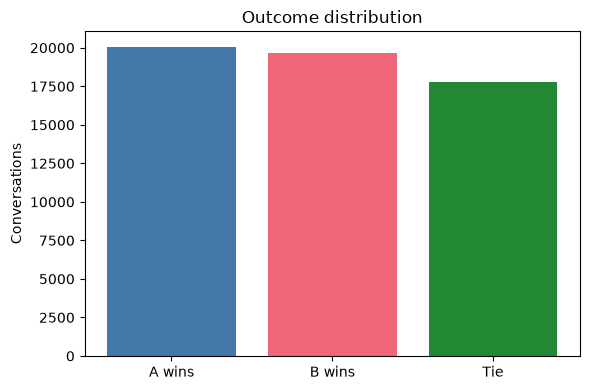

In [11]:
import matplotlib.pyplot as plt

# Number of conversations for each outcome.
class_counts = df[TARGET_COLS].sum()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["A wins", "B wins", "Tie"], class_counts, color=["#4477AA", "#EE6677", "#228833"])
ax.set_title("Outcome distribution")
ax.set_ylabel("Conversations")
fig.tight_layout()
plt.show()


**Target balance.** The three outcomes are close to balanced: A wins 20,064 times (34.9%), B wins 19,652 times (34.2%) and ties happen 17,761 times (30.9%). A is preferred slightly more often than B (0.7 percentage points), which is small. Because no class dominates, accuracy would be a poor way to judge a model here, and a constant prediction of the class proportions already gets a log loss close to the uniform value of 1.0986 (we measure it in Section 5).

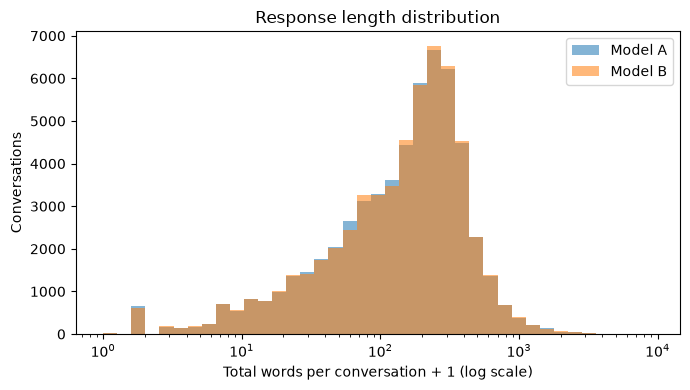

In [12]:
# Logarithmic bins show the long tail without dropping long responses.
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.geomspace(1, max(a_words.max(), b_words.max()) + 2, 40)
ax.hist(a_words + 1, bins=bins, alpha=0.55, label="Model A")
ax.hist(b_words + 1, bins=bins, alpha=0.55, label="Model B")
ax.set_xscale("log")
ax.set_title("Response length distribution")
ax.set_xlabel("Total words per conversation + 1 (log scale)")
ax.set_ylabel("Conversations")
ax.legend()
fig.tight_layout()
plt.show()


**Response length distribution.** The median response has about 170 words, but lengths range from 0 to over 9,000 words, so we used a logarithmic x-axis. Most responses lie between roughly 100 and 500 words. A tail of very short responses stretches to the left (5.17% have 10 words or fewer, with a small bump at a single word: 1,282 responses) and a thin tail of very long responses to the right. The histograms of model A and model B almost overlap (mean 212.3 vs 213.2 words), so the position of a response (A or B) does not change how long it is, and any length effect we see below is not caused by one slot systematically holding longer answers.

In [13]:
# Outliers: how long is "too long"? We use the usual IQR rule on all responses.
all_words = pd.concat([a_words, b_words])
q1, q3 = all_words.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)

print(f"Q1 = {q1:.0f} words, Q3 = {q3:.0f} words, IQR upper fence = {upper_fence:.0f} words")
print(f"Responses above the fence: {(all_words > upper_fence).mean() * 100:.2f}%")
print(f"Responses with more than 2,000 words: {(all_words > 2000).sum()}")
print(f"Responses with more than 5,000 words: {(all_words > 5000).sum()}")
print(f"Longest response: {all_words.max()} words")
print(f"Responses with 0 words: {(all_words == 0).sum()}")
print(f"Responses with exactly 1 word: {(all_words == 1).sum()}")
print(f"Responses with 10 words or fewer: {(all_words <= 10).mean() * 100:.2f}%")
display(all_words.describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]).round(1).to_frame("words"))

Q1 = 66 words, Q3 = 290 words, IQR upper fence = 626 words
Responses above the fence: 3.68%
Responses with more than 2,000 words: 188
Responses with more than 5,000 words: 5
Longest response: 9184 words
Responses with 0 words: 64
Responses with exactly 1 word: 1282
Responses with 10 words or fewer: 5.17%


,words
count,114954.0
mean,212.8
std,227.4
min,0.0
50%,170.0
90%,420.0
95%,559.0
99%,1042.0
99.9%,2312.1
max,9184.0


**Outliers.** By the IQR rule, responses longer than 626 words are outliers: 3.68% of all responses. The extreme tail is short but very long: 188 responses have more than 2,000 words and 5 have more than 5,000 (the longest has 9,184 words). At the other end, 64 responses have 0 words (they contain only empty or null turns). These long responses are real model answers, not errors, so we **keep them**. Instead we reduce their influence by scaling the features (Section 4) and we note that a logarithmic transform of the lengths is a candidate improvement for Assignment 2.

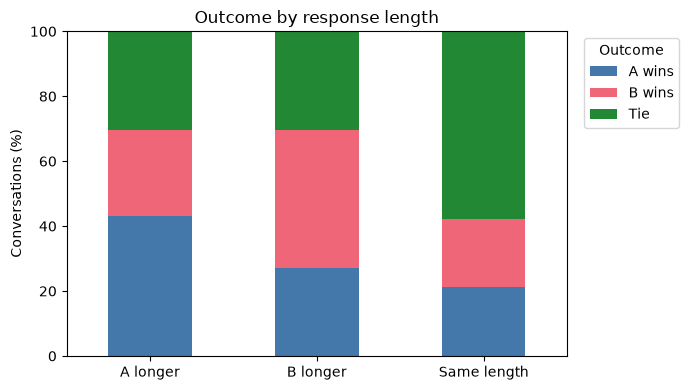

In [14]:
# The percentages in each length group add up to 100.
plot_rates = outcome_rates.reindex(
    index=["A longer", "B longer", "Same length"],
    columns=["A wins", "B wins", "Tie"]
).copy()
plot_rates.index = ["A longer", "B longer", "Same length"]
plot_rates.columns = ["A wins", "B wins", "Tie"]
ax = plot_rates.plot.bar(
    stacked=True, figsize=(7, 4), color=["#4477AA", "#EE6677", "#228833"], rot=0
)
ax.set_title("Outcome by response length")
ax.set_xlabel("")
ax.set_ylabel("Conversations (%)")
ax.set_ylim(0, 100)
ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
fig = ax.figure
fig.tight_layout()
plt.show()


**Outcome by response length.** The longer response is preferred noticeably more often: in each "longer" group the longer side wins about 43% of the time against about 27% for the shorter side. The tie share is almost constant (30.4%) in both of those groups, but jumps to 57.8% when the lengths are equal: equal-length responses are often the same answer (in 275 rows `response_a` and `response_b` are identical, and 90.2% of those are ties), so a human cannot prefer either. Length therefore helps with *both* the A-vs-B decision and the tie decision. We have to be careful, though: this is an association, not proof that longer responses are better; longer answers may simply be more complete.

Rows used: 39273; longer response wins in 61.4% of them


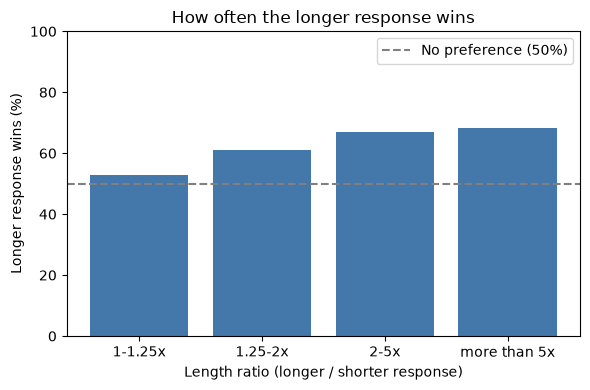

1-1.25x         52.8
1.25-2x         61.0
2-5x            67.1
more than 5x    68.4


In [15]:
# Among rows with a decision (no tie) and different lengths: how often does the longer response win?
decided = (a_words != b_words) & (encode_target(df) != 2)
y_all = encode_target(df)
longer_wins = np.where(a_words > b_words, y_all == 0, y_all == 1)
length_ratio = np.maximum(a_words, b_words) / np.maximum(1, np.minimum(a_words, b_words))

ratio_bins = pd.cut(length_ratio[decided], [1, 1.25, 2, 5, np.inf],
                    labels=["1-1.25x", "1.25-2x", "2-5x", "more than 5x"])
win_rate = pd.Series(longer_wins[decided]).groupby(ratio_bins.values, observed=True).mean() * 100
print(f"Rows used: {decided.sum()}; longer response wins in {longer_wins[decided].mean() * 100:.1f}% of them")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(win_rate.index.astype(str), win_rate.values, color="#4477AA")
ax.axhline(50, color="grey", linestyle="--", label="No preference (50%)")
ax.set_title("How often the longer response wins")
ax.set_xlabel("Length ratio (longer / shorter response)")
ax.set_ylabel("Longer response wins (%)")
ax.set_ylim(0, 100)
ax.legend()
fig.tight_layout()
plt.show()
print(win_rate.round(1).to_string())

**Strength of the length effect.** Excluding ties and equal-length pairs (39,273 rows), the longer response wins 61.4% of the time. The effect grows with the length gap: 52.8% when the lengths differ by less than 25%, 61.0% for a ratio between 1.25 and 2, 67.1% between 2 and 5, and 68.4% above 5. It levels off at the largest gaps, which suggests that length is useful but has a ceiling, and the content of the response must matter as well.

**What this means for modelling.** (1) Response length is a cheap feature with a real signal, so we use it for the baseline. (2) The ratio or difference of the two lengths matters more than the absolute length, which is why we include the word difference. (3) Model names are not available at test time, so the outcome of a comparison has to be predicted from the text alone.

## 4. Preprocessing

Decisions and the reasons for them:

1. **No rows are removed or filled in.** Rows with a null or blank turn affect only 5 prompts, 133 `response_a` and 143 `response_b` entries (well under 1% of the 57,477 rows), and the 71 repeated prompt-response combinations are also rare. Deleting them would change little, and the real test data may contain the same defects, so the pipeline has to cope with them anyway. The word-count function simply skips null turns.
2. **Parse the JSON lists.** Each text column is a JSON list of turns, so we parse it and count the words over all turns of a response (`src.data.word_count`).
3. **Features.** `a_words`, `b_words` and `word_diff = a_words - b_words`. The difference captures the *relative* length, which the exploration showed to be the informative part.
4. **Scale the features** with `StandardScaler`. Logistic regression is sensitive to feature scale, and the word counts are heavy-tailed (maximum 9,184 words), so standardizing keeps the optimization stable.
5. **One label for the target.** The three one-hot columns become a single label (0 = A wins, 1 = B wins, 2 = tie).
6. **Stratified 80/20 train-validation split** with `random_state=42`, so the three classes keep the same proportions in both parts and results can be reproduced.

Limitation: repeated conversations may land in both the training and the validation part, which can make the validation score slightly optimistic.

In [16]:
X = features                      # a_words, b_words, word_diff (computed in Section 3)
y = encode_target(df)             # 0 = A wins, 1 = B wins, 2 = tie
train_idx, val_idx = stratified_split(y, test_size=0.20, seed=42)

print("Training rows:  ", len(train_idx))
print("Validation rows:", len(val_idx))
print("Class shares in training:  ", (np.bincount(y[train_idx]) / len(train_idx)).round(4))
print("Class shares in validation:", (np.bincount(y[val_idx]) / len(val_idx)).round(4))
display(X.iloc[train_idx].describe().round(1))

Training rows:   45981
Validation rows: 11496
Class shares in training:   [0.3491 0.3419 0.309 ]
Class shares in validation: [0.3491 0.3419 0.309 ]


,a_words,b_words,word_diff
count,45981.0,45981.0,45981.0
mean,213.0,213.9,-0.8
std,225.1,232.4,164.9
min,0.0,0.0,-7993.0
25%,66.0,67.0,-68.0
50%,170.0,170.0,0.0
75%,289.0,291.0,67.0
max,4247.0,8173.0,2646.0


The stratified split keeps the class shares practically identical in both parts (A about 34.9%, B about 34.2%, tie about 30.9%). The summary of the training features shows the skew we discussed: the mean number of words is well above the median and the maximum is far larger than the 75th percentile, which is why the features are standardized before the logistic regression.

## 5. Baseline models

We use two baselines and compare them with the competition metric (log loss) on the same validation split:

1. **Class proportions:** predict the training class shares for every row, ignoring the text completely. It shows the score of a model that knows nothing about the responses.
2. **Response length + logistic regression:** standardized `a_words`, `b_words` and `word_diff` as inputs.

Later models have to beat both.

In [17]:
val_probs = class_prior_probs(y[train_idx], len(val_idx))
prior_score = log_loss(y[val_idx], val_probs, labels=[0, 1, 2])
print(f"Validation log loss = {prior_score:.4f}")

Validation log loss = 1.0972


Predicting the class proportions gives a validation log loss of **1.0972**, only slightly below the 1.0986 of a uniform guess, because the classes are close to balanced.

In [18]:
model = build_length_model()
model.fit(X.iloc[train_idx], y[train_idx])

proba = model.predict_proba(X.iloc[val_idx])
length_score = log_loss(y[val_idx], proba, labels=[0, 1, 2])

print(f"Class-prior baseline:            {prior_score:.4f}")
print(f"Length + logistic regression:    {length_score:.4f}")
print(f"Improvement: {prior_score - length_score:.4f} ({(prior_score - length_score) / prior_score * 100:.1f}% relative)")

Class-prior baseline:            1.0972
Length + logistic regression:    1.0709
Improvement: 0.0263 (2.4% relative)


| Baseline | Validation log loss |
| --- | ---: |
| Class proportions | 1.0972 |
| Response length + logistic regression | 1.0709 |

Adding only three length features lowers the log loss by 0.0263 (about 2.4%). The gain is small but consistent with the exploration: length carries some information about who wins and about ties. The model cannot see the *content* of the responses, so it has a low ceiling.

## 6. Kaggle submission

The competition is an ongoing *Code Competition* with a rolling leaderboard: scoring happens on a hidden test set, and submissions must be made from a Kaggle notebook (internet off, output file named `submission.csv`). The downloaded `test.csv` contains only 3 example rows. We therefore (a) produce a submission file in the official format with the length baseline, and (b) report the validation score on the held-out 20% of `train.csv` as our evaluation.

In [19]:
# Fit on all labelled data, predict the test rows and write the submission file.
test = load_test()
final_model = build_length_model().fit(X, y)
test_proba = final_model.predict_proba(length_features(test))

path = save_submission(test["id"], test_proba, "submissions/baseline_length_lr.csv")

# Format check against the official sample submission.
sample = pd.read_csv("data/sample_submission.csv")
submission = pd.read_csv(path)
assert list(submission.columns) == list(sample.columns)
assert (submission["id"].to_numpy() == sample["id"].to_numpy()).all()
assert np.allclose(submission[TARGET_COLS].sum(axis=1), 1.0)
print("Saved:", path)
display(submission)

Saved: submissions/baseline_length_lr.csv


,id,winner_model_a,winner_model_b,winner_tie
0,136060,0.326120,0.338888,0.334992
1,211333,0.432710,0.252470,0.314820
2,1233961,0.461268,0.262659,0.276073


The file passes the format check (same columns and ids as `sample_submission.csv`, probabilities sum to 1 in every row). With only 3 example rows it says nothing about quality.

**Scores.** Held-out validation log loss from Section 5: **1.0709** for the length baseline and **1.0972** for the class proportions. Kaggle public score of the submitted length baseline: **1.07607**.

**Kaggle score.** We submitted the length baseline from a Kaggle notebook (`kaggle_submission.ipynb`: same features, scaling and logistic regression, fitted on all 57,477 labelled rows). The competition scored it with **public log loss = 1.07607**. This is very close to our held-out validation score of 1.0709 (difference 0.0052), which suggests that the validation split was a reasonable estimate of the hidden test performance and that the possible overlap of repeated conversations did not inflate it much. It is also clearly better than the uniform guess (ln 3 = 1.0986) and the class-proportion baseline (1.0972 on validation), but only by a small margin: we are far from the top of the leaderboard, which needs models that read the response *content*. The score evidence is saved in `submissions/` (screenshot of the submission page).

## 7. Conclusions and next steps

The dataset contains 57,477 comparisons with three relatively balanced outcomes: model A wins (34.91%), model B wins (34.19%), and ties (30.90%). Although there are no column-level missing values or fully duplicated rows, some conversation lists contain null or blank turns, and 71 additional rows repeat the same prompt-response combination. All conversation lists have valid structures and matching turn counts, and all rows have valid winner labels.

The exploratory analysis shows an association between response length and user preference. When A is longer, A wins in 43.1% of comparisons, while B wins in 26.6%. When B is longer, B wins in 42.4% of comparisons, while A wins in 27.2%. Equal-length responses result in a tie in 57.8% of cases. These findings motivated using response word counts and their difference as baseline features. However, this association does not show that making a response longer causes it to be preferred.

Both baselines were evaluated on the same stratified 80/20 train-validation split with a random seed of 42. Lower log loss indicates better probability predictions.

| Baseline | Validation log loss |
| --- | ---: |
| Training class proportions | 1.0972 |
| Response length + logistic regression | 1.0709 |

Logistic regression reduced validation log loss by 0.0263, approximately 2.4% relative to the class-proportion baseline. This modest improvement suggests that response length provides useful predictive information, but the model does not directly capture response content, correctness, or relevance to the prompt.

These results provide an initial reference for future models. They are based on a single validation split, and repeated conversations may appear in both training and validation, potentially making the scores optimistic. In the next stage, we plan to evaluate TF-IDF text features with logistic regression and use a validation split that keeps repeated conversations together. This will help assess whether text features improve predictions beyond response length under a more reliable evaluation setup.